In [1]:
from dask.distributed import Client

client = Client("tcp://127.0.0.1:35724")
client

<Client: 'tcp://127.0.0.1:35724' processes=8 threads=32, memory=503.70 GiB>

In [11]:
import numpy as np
import xarray as xr
import os.path as op
import gsw

from xgcm.grid import Grid
from scipy.optimize import curve_fit

import geostrokit as qg

import cartopy.crs as ccrs
import cartopy.feature as cfeature
import cmocean

import matplotlib.pyplot as plt
%matplotlib inline

In [3]:
ddir = "/storage/tartar/takaya/bruno/basilisk/"

In [4]:
for pp in range(84,90):
    if pp == 84:
        ds = xr.open_dataset(op.join(ddir,"QG/vars_%04d.nc" % pp)
                            ).isel(level=slice(None,None)
                                  ).chunk({"time":4,"level":1,"y":125,"x":256})
    else:
        tmp = xr.open_dataset(op.join(ddir,"QG/vars_%04d.nc" % pp)
                            ).isel(time=slice(1,None),
                                   level=slice(None,None)
                                  ).chunk({"time":4,"level":1,"y":125,"x":256}
                                         )
        time = tmp.time.data + ds.time[-1].data
        tmp = tmp.reset_index("time", drop=False)
        tmp = tmp.reset_coords("time", drop=True)
        tmp.coords["time"] = ("time", time)
        ds = xr.concat([ds, tmp], "time")
        tmp.close()
    
ds

<xarray.Dataset> Size: 60GB
Dimensions:  (time: 718, level: 5, y: 1025, x: 2049)
Coordinates:
  * time     (time) float32 3kB 0.0 2.592e+06 5.184e+06 ... 1.856e+09 1.858e+09
  * level    (level) float32 20B 0.0 1.0 2.0 3.0 4.0
  * y        (y) float32 4kB 0.0 3.906e+03 7.812e+03 ... 3.996e+06 4e+06
  * x        (x) float32 8kB 0.0 3.906e+03 7.812e+03 ... 7.996e+06 8e+06
Data variables:
    psi      (time, level, y, x) float32 30GB dask.array<chunksize=(4, 1, 125, 256), meta=np.ndarray>
    q        (time, level, y, x) float32 30GB dask.array<chunksize=(4, 1, 125, 256), meta=np.ndarray>

In [ ]:
dsave = ds.mean("time")
print(dsave)
dsave.chunk({"level":1,"y":125,"x":256}
           ).to_zarr(op.join(ddir,"QG/mean/qPsi.zarr"), mode="w")
dsave.close()

<xarray.Dataset> Size: 84MB
Dimensions:  (level: 5, y: 1025, x: 2049)
Coordinates:
  * level    (level) float32 20B 0.0 1.0 2.0 3.0 4.0
  * y        (y) float32 4kB 0.0 3.906e+03 7.812e+03 ... 3.996e+06 4e+06
  * x        (x) float32 8kB 0.0 3.906e+03 7.812e+03 ... 7.996e+06 8e+06
Data variables:
    psi      (level, y, x) float32 42MB dask.array<chunksize=(1, 125, 256), meta=np.ndarray>
    q        (level, y, x) float32 42MB dask.array<chunksize=(1, 125, 256), meta=np.ndarray>


/storage/tartar/takaya/miniconda3/envs/basil/lib/python3.12/site-packages/zarr/api/asynchronous.py:231: ZarrUserWarning: Consolidated metadata is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  warnings.warn(
/storage/tartar/takaya/miniconda3/envs/basil/lib/python3.12/site-packages/distributed/client.py:3398: UserWarning: Sending large graph of size 15.70 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(


In [5]:
dsin = xr.open_dataset(op.join(ddir,"QG/input_vars_5l_N2048.nc")
                      ).isel(t=0)
mask = dsin.mask
try:
  mask0 = dsin.mask0
except:
  mask0 = dsin.coastlines

mask0_nan = np.where(mask0 == 0, np.nan, 1)
mask0_c_nan = mask0_nan[:-1,:-1]
mask0_nan, mask0_c_nan

(array([[ 1.,  1.,  1., ...,  1.,  1.,  1.],
        [ 1.,  1.,  1., ...,  1.,  1.,  1.],
        [ 1.,  1.,  1., ...,  1.,  1.,  1.],
        ...,
        [nan, nan, nan, ...,  1.,  1.,  1.],
        [nan, nan, nan, ...,  1.,  1.,  1.],
        [nan, nan, nan, ...,  1.,  1.,  1.]], shape=(1025, 2049)),
 array([[ 1.,  1.,  1., ...,  1.,  1.,  1.],
        [ 1.,  1.,  1., ...,  1.,  1.,  1.],
        [ 1.,  1.,  1., ...,  1.,  1.,  1.],
        ...,
        [nan, nan, nan, ...,  1.,  1.,  1.],
        [nan, nan, nan, ...,  1.,  1.,  1.],
        [nan, nan, nan, ...,  1.,  1.,  1.]], shape=(1024, 2048)))

<xarray.DataArray (level: 5, y: 1025, x: 2049, li: 4)> Size: 336MB
dask.array<mul, shape=(5, 1025, 2049, 4), dtype=float64, chunksize=(1, 125, 256, 4), chunktype=numpy.ndarray>
Coordinates:
  * level    (level) float32 20B 0.0 1.0 2.0 3.0 4.0
  * y        (y) float32 4kB 0.0 3.906e+03 7.812e+03 ... 3.996e+06 4e+06
  * x        (x) float32 8kB 0.0 3.906e+03 7.812e+03 ... 7.996e+06 8e+06
  * li       (li) float64 32B 0.5 1.5 2.5 3.5
<xarray.DataArray (li: 4)> Size: 32B
array([4.04e-05, 1.60e-05, 1.24e-05, 2.52e-06])
Coordinates:
  * li       (li) float64 32B 0.5 1.5 2.5 3.5 [ -125.  -375.  -625.  -875. -2500.] [    0.  -250.  -500.  -750. -1000. -4000.]


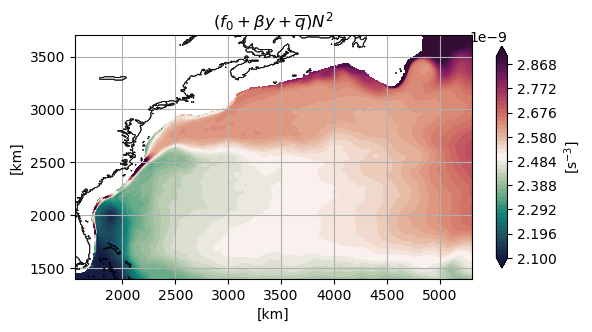

In [6]:
dsb = xr.open_zarr(op.join(ddir,"QG/mean/qPsi.zarr"))
N2 = xr.DataArray(np.array([4.04e-05, 1.6e-05, 1.24e-05, 2.52e-06,]), 
                  dims="li",
                  coords={"li":np.array([0.5,1.5,2.5,3.5])}
                 )
print(dsb.q*N2)
dz = xr.DataArray(np.array([250,250,250,250,3000]), 
                  dims="level",
                  coords={"level":dsb.level.data}
                 )
Zp1 = np.concatenate((np.array([0.,]), -np.cumsum(dz.data)))
Z = .5*(Zp1[1:]+Zp1[:-1])
print(N2,Z,Zp1)

dsb["Zp1"] = xr.DataArray(Zp1, dims="lp1",
                          coords={"lp1":np.array([-.5,0.5,1.5,2.5,3.5,4.5])}
                         )
dsb["Z"] = xr.DataArray(Z, dims="level",
                        coords={"level":dsb.level.data}
                       )
dsb["N2"] = N2

dsb.coords["yG"] = ("yG",.5*(dsb.y.data[1:]+dsb.y.data[:-1]))
dsb.coords["xG"] = ("xG",.5*(dsb.x.data[1:]+dsb.x.data[:-1]))

grid = Grid(dsb, periodic=None, autoparse_metadata=False,
            coords={"X": {"center": "x", "inner": "xG"},
                    "Y": {"center": "y", "inner": "yG"},
                    "Z": {"center": "level", "outer": "lp1", "inner": "li"}
                   })

xmax = 5300
xmin = 1550
ymin = 1400
ymax = 3700

f0 = 7.3e-05
beta = 2e-11

fig, ax = plt.subplots()
ax.set_xlim([xmin, xmax], 
              # crs=ccrs.PlateCarree()
           )
ax.set_ylim([ymin, ymax], 
              # crs=ccrs.PlateCarree()
           )

# im = ax.pcolormesh(dsb.x*1e-3, dsb.y*1e-3, 
#                    ((f0 + beta*dsb.y + dsb.q)
#                     * grid.interp(N2,"Z",boundary="extend")
#                    ).isel(level=1),
#                    vmin=2.6e-9, vmax=4.3e-9,
#                    cmap=cmocean.cm.matter,
#                   )
im = ax.contourf(dsb.x*1e-3, dsb.y*1e-3, 
                 ((f0 + beta*(dsb.y - dsb.y.mean()) + dsb.q)
                  * grid.interp(N2,"Z",boundary="extend")
                 ).where(dsb.q!=0.).isel(level=1), 
                 cmap=cmocean.cm.curl,
                 levels=np.linspace(2.1e-9,2.9e-9,51),
                 extend="both"
                )

ax.contour(dsb.x[::2]*1e-3, dsb.y[::2]*1e-3, mask0[::2,::2], 
           colors="k", linewidths=.2, zorder=10)

ax.set_rasterized(True)
ax.set_ylabel(r"[km]")
ax.set_xlabel(r"[km]")
ax.set_aspect("equal")
ax.grid(True)

ax.set_title(r"$(f_0 + \beta y + \overline{q})N^2$", fontsize=12)
cb = fig.colorbar(im, ax=ax, shrink=.6)
cb.set_label(r"[s$^{-3}$]")
plt.savefig(op.join(ddir,"Figs/qbarN2.pdf"), dpi=200)

In [44]:
((f0 + beta*(dsb.y - dsb.y.mean()) + dsb.q)
                  * grid.interp(N2,"Z",boundary="extend")
                 ).where(dsb.q!=0.).sel(x=3600e3,method='nearest'), dsb.Z, dsb.y

(<xarray.DataArray (y: 1025, level: 5)> Size: 41kB
 dask.array<getitem, shape=(1025, 5), dtype=float64, chunksize=(125, 1), chunktype=numpy.ndarray>
 Coordinates:
   * y        (y) float32 4kB 0.0 3.906e+03 7.812e+03 ... 3.996e+06 4e+06
   * level    (level) float32 20B 0.0 1.0 2.0 3.0 4.0
     x        float32 4B 3.602e+06,
 <xarray.DataArray 'Z' (level: 5)> Size: 40B
 array([ -125.,  -375.,  -625.,  -875., -2500.])
 Coordinates:
   * level    (level) float32 20B 0.0 1.0 2.0 3.0 4.0,
 <xarray.DataArray 'y' (y: 1025)> Size: 4kB
 array([0.000000e+00, 3.906250e+03, 7.812500e+03, ..., 3.992188e+06,
        3.996094e+06, 4.000000e+06], shape=(1025,), dtype=float32)
 Coordinates:
   * y        (y) float32 4kB 0.0 3.906e+03 7.812e+03 ... 3.996e+06 4e+06)

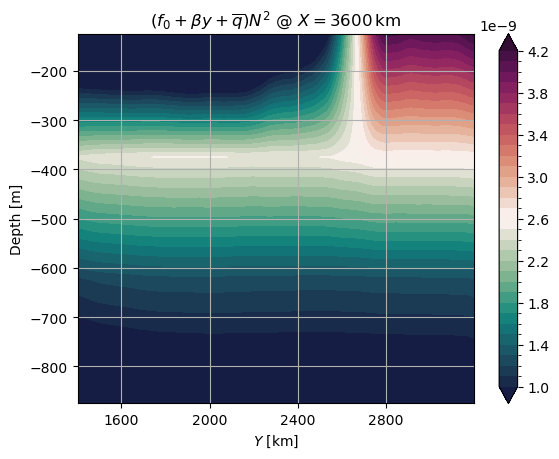

In [57]:
ymin = 1400
ymax = 3700

f0 = 7.3e-05
beta = 2e-11

fig, ax = plt.subplots()

field = (
    (f0 + beta*(dsb.y - dsb.y.mean()) + dsb.q)
    * grid.interp(N2, "Z", boundary="extend")
).where(dsb.q != 0.).sel(x=3600e3, method="nearest"
                        ).sel(y=slice(ymin*1e3, 3200e3)
                             ).isel(level=slice(None,-1))

# 2. Attach Z (depth) as a coordinate on the level dim
field = field.assign_coords(Z=("level", 
                               dsb.Z.isel(level=slice(None,-1)).values))

# 3. Plot: x = y, y = Z (depth)
field.plot.contourf(
    x="y",
    y="Z",
    cmap=cmocean.cm.curl,
    ax=ax,
    levels=np.linspace(1e-9,4.2e-9,33),
    extend="both"
)

ax.set_xticks([1.6e6,2e6,2.4e6,2.8e6])
ax.set_xticklabels([1600,2000,2400,2800])

ax.set_ylabel(r"Depth [m]")
ax.set_xlabel(r"$Y$ [km]")
ax.grid(True)
ax.set_rasterized(True)
ax.set_title(r"$(f_0 + \beta y + \overline{q})N^2$ @ $X=3600\,$km", fontsize=12)
plt.savefig(op.join(ddir,"Figs/qbarN2_3600km.pdf"), dpi=200)

In [7]:
dsave = (ds.q - dsb.q).to_dataset(name="qp")
dsave["pp"] = ds.psi - dsb.psi
print(dsave)
dsave.chunk({"time":4,"level":1,"y":125,"x":256}
           ).to_zarr(op.join(ddir,"QG/eddy/qPsi.zarr"), mode="w")
dsave.close()

<xarray.Dataset> Size: 60GB
Dimensions:  (time: 718, y: 1025, x: 2049, level: 5)
Coordinates:
  * time     (time) float32 3kB 0.0 2.592e+06 5.184e+06 ... 1.856e+09 1.858e+09
  * y        (y) float32 4kB 0.0 3.906e+03 7.812e+03 ... 3.996e+06 4e+06
  * x        (x) float32 8kB 0.0 3.906e+03 7.812e+03 ... 7.996e+06 8e+06
  * level    (level) float32 20B 0.0 1.0 2.0 3.0 4.0
Data variables:
    qp       (time, level, y, x) float32 30GB dask.array<chunksize=(4, 1, 125, 256), meta=np.ndarray>
    pp       (time, level, y, x) float32 30GB dask.array<chunksize=(4, 1, 125, 256), meta=np.ndarray>


/storage/tartar/takaya/miniconda3/envs/basil/lib/python3.12/site-packages/zarr/api/asynchronous.py:231: ZarrUserWarning: Consolidated metadata is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  warnings.warn(
/storage/tartar/takaya/miniconda3/envs/basil/lib/python3.12/site-packages/distributed/client.py:3398: UserWarning: Sending large graph of size 50.98 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(


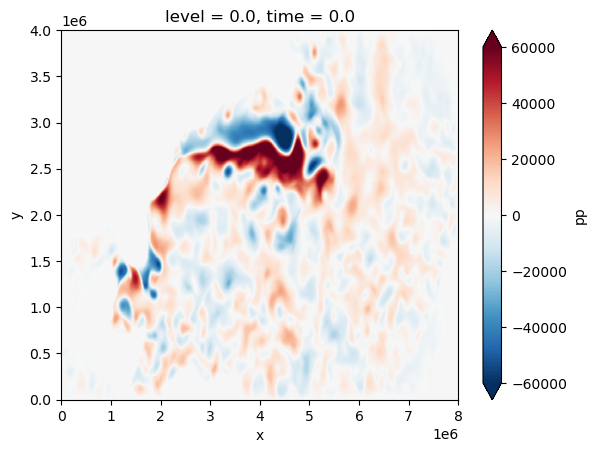

In [11]:
dsp = xr.open_zarr(op.join(ddir,"QG/eddy/qPsi.zarr"))
dsp.pp.isel(time=0,level=0).plot(rasterized=True, vmax=6e4)

In [10]:
N2 = xr.DataArray(np.array([4.04e-05, 1.6e-05, 1.24e-05, 2.52e-06,]), 
                  dims="li",
                  coords={"li":np.array([0.5,1.5,2.5,3.5])}
                 )
dz = xr.DataArray(np.array([250,250,250,250,3000]), 
                  dims="level",
                  coords={"level":ds.level.data}
                 )
Zp1 = np.concatenate((np.array([0.,]), -np.cumsum(dz.data)))
Z = .5*(Zp1[1:]+Zp1[:-1])
print(N2,Z,Zp1)

ds["Zp1"] = xr.DataArray(Zp1, dims="lp1",
                         coords={"lp1":np.array([-.5,0.5,1.5,2.5,3.5,4.5])}
                        )
ds["Z"] = xr.DataArray(Z, dims="level",
                       coords={"level":ds.level.data}
                      )
ds["N2"] = N2

# llo, lla = np.meshgrid(dsp.x, dsp.y)
# xxG = xr.DataArray(gsw.distance(llo, lla), dims=["y","xG"],
#                   coords={"y":dsp.y.data,
#                           "xG":.5*(dsp.x.data[1:]+dsp.x.data[:-1])}
#                  )
# yyG = xr.DataArray(gsw.distance(llo, lla, axis=0), dims=["yG","x"],
#                   coords={"yG":.5*(dsp.y.data[1:]+dsp.y.data[:-1]),
#                           "x":dsp.x.data}
#                  )
ds.coords["yG"] = ("yG",.5*(ds.y.data[1:]+ds.y.data[:-1]))
ds.coords["xG"] = ("xG",.5*(ds.x.data[1:]+ds.x.data[:-1]))

grid = Grid(ds, padding={'X': 'extend', 'Y': 'extend', "Z": "extend"},  
            autoparse_metadata=False,
            coords={"X": {"center": "x", "inner": "xG"},
                    "Y": {"center": "y", "inner": "yG"},
                    "Z": {"center": "level", "outer": "lp1", "inner": "li"}
                   })

f0 = 7.3e-05
b = (grid.diff(ds.psi.fillna(0.).chunk({"level":-1}),
                "Z",boundary="extend",to="inner")
     / grid.diff(ds.Z,"Z",boundary="extend",to="inner")
    ) * f0

<xarray.DataArray (li: 4)> Size: 32B
array([4.04e-05, 1.60e-05, 1.24e-05, 2.52e-06])
Coordinates:
  * li       (li) float64 32B 0.5 1.5 2.5 3.5 [ -125.  -375.  -625.  -875. -2500.] [    0.  -250.  -500.  -750. -1000. -4000.]


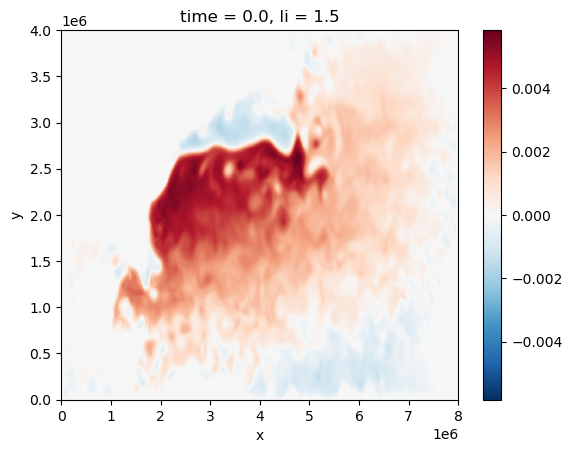

In [15]:
b.isel(time=0,li=1).plot()

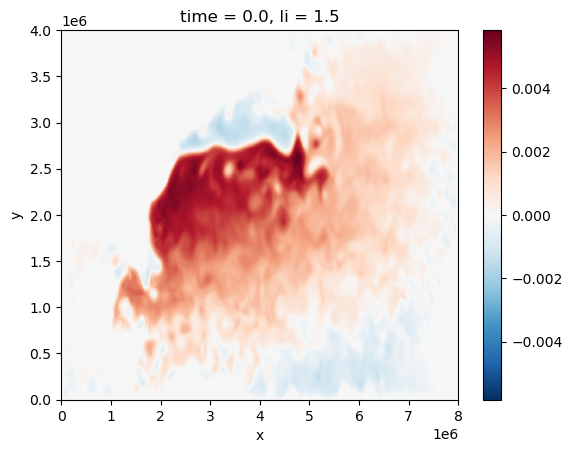

In [16]:
bkit = xr.DataArray(qg.p2b(ds.psi.isel(time=0).values, dz.values, f0),
                    dims = b.isel(time=0).dims,
                    coords = b.isel(time=0).coords)
bkit.isel(li=1).plot()